# Experiment 12 — Hierarchical Clustering and Dendrogram Analysis

**Aim:** Perform agglomerative hierarchical clustering, visualize dendrograms, and compare linkage methods.

**Libraries:** pandas, NumPy, Matplotlib, SciPy, and scikit-learn.

**Theory:** Agglomerative clustering repeatedly merges groups. Single, complete, and Ward linkage define different merge costs; a dendrogram displays the merge hierarchy.

**Dataset:** The supplied Palmer Penguins CSV is used. Four body measurements and species are selected; rows missing any selected value are removed. Dendrograms use a reproducible 100-row subset for readability; clustering evaluation uses every cleaned row.

## Procedure / Implementation
The following cells load the data, apply the stated method, produce outputs, and record observations.


Dataset source: datasets/penguins.csv (extracted from supplied archive (3).zip)
Original shape: (344, 19) | cleaned selected data: (342, 5)
Measurement columns: ['Culmen Length (mm)', 'Culmen Depth (mm)', 'Flipper Length (mm)', 'Body Mass (g)']
Species counts after dropping missing selected values:
Species
Adelie Penguin (Pygoscelis adeliae)          151
Gentoo penguin (Pygoscelis papua)            123
Chinstrap penguin (Pygoscelis antarctica)     68
Dendrogram subset: 100 of 342 cleaned rows, selected with random_state=42. Full data is used below for clustering evaluation.


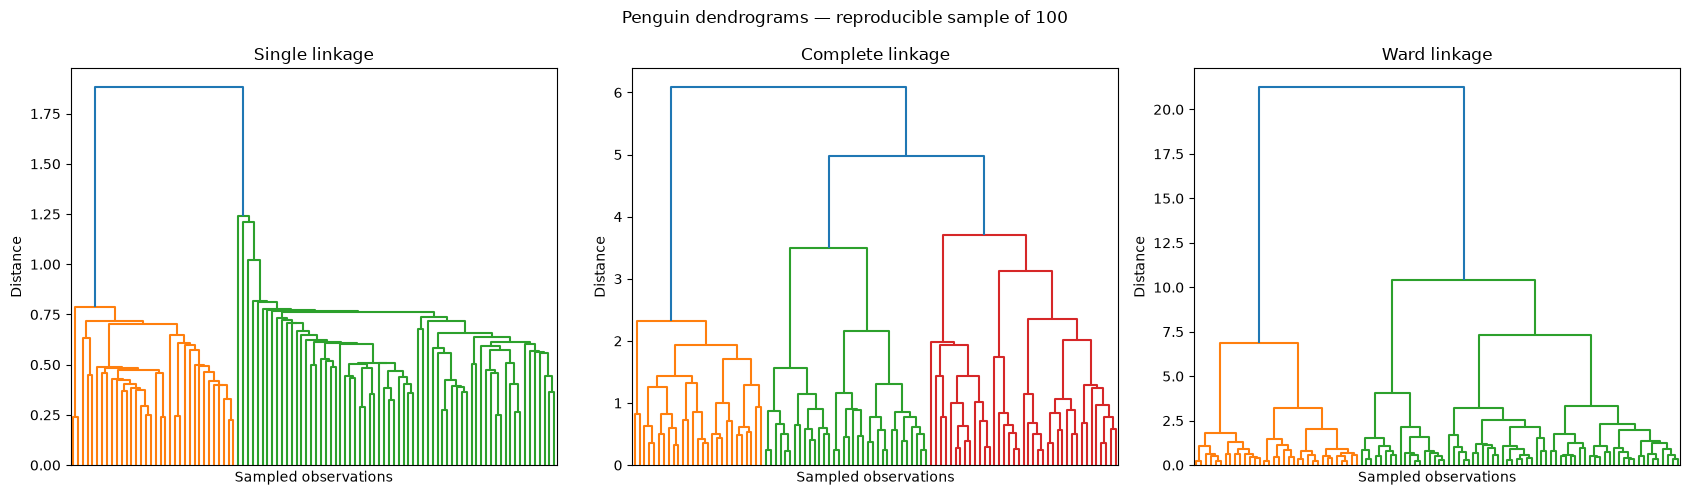

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

SEED = 42
ROOT = Path.cwd()
if not (ROOT / 'datasets').is_dir():
    ROOT = ROOT.parent
FIGURES = ROOT / 'outputs' / 'figures'
RESULTS = ROOT / 'outputs' / 'results'
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
penguins_path = ROOT / 'datasets' / 'penguins.csv'
if penguins_path.is_file():
    penguins = pd.read_csv(penguins_path)
    data_source = 'datasets/penguins.csv (extracted from supplied archive (3).zip)'
else:
    penguins = pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv')
    data_source = 'Palmer Penguins CSV source'

column_options = [
    ('Species', ['Culmen Length (mm)', 'Culmen Depth (mm)', 'Flipper Length (mm)', 'Body Mass (g)']),
    ('species', ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']),
]
selection = next(((species_column, feature_columns) for species_column, feature_columns in column_options if set([species_column, *feature_columns]).issubset(penguins.columns)), None)
if selection is None:
    raise ValueError(f'Penguin dataset does not contain the expected species and measurement columns. Found: {list(penguins.columns)}')
species_column, feature_columns = selection
cleaned = penguins[[species_column, *feature_columns]].dropna().reset_index(drop=True)
X = cleaned[feature_columns].astype(float)
species = cleaned[species_column].astype(str)
print('Dataset source:', data_source)
print('Original shape:', penguins.shape, '| cleaned selected data:', cleaned.shape)
print('Measurement columns:', feature_columns)
print('Species counts after dropping missing selected values:')
print(species.value_counts().to_string())
X_scaled = StandardScaler().fit_transform(X)

linkage_methods = ['single', 'complete', 'ward']
subset_size = min(100, len(cleaned))
subset_indices = np.random.default_rng(SEED).choice(len(cleaned), size=subset_size, replace=False)
print(f'Dendrogram subset: {subset_size} of {len(cleaned)} cleaned rows, selected with random_state={SEED}. Full data is used below for clustering evaluation.')
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for axis, method in zip(axes, linkage_methods):
    tree = linkage(X_scaled[subset_indices], method=method)
    dendrogram(tree, ax=axis, no_labels=True, color_threshold=None)
    axis.set_title(f'{method.capitalize()} linkage')
    axis.set_xlabel('Sampled observations')
    axis.set_ylabel('Distance')
fig.suptitle(f'Penguin dendrograms — reproducible sample of {subset_size}')
fig.tight_layout()
fig.savefig(FIGURES / 'exp12_dendrograms.png', dpi=150, bbox_inches='tight')
plt.show()

## Cluster the full cleaned dataset and compare species

Each linkage method creates three clusters from the full standardised dataset. Cluster numbers are arbitrary, so the adjusted Rand index is used as a label-permutation-invariant summary alongside the contingency tables.

--- Single linkage: ARI = 0.6572 ---
Cluster                                      0  1    2
Actual species                                        
Adelie Penguin (Pygoscelis adeliae)        151  0    0
Chinstrap penguin (Pygoscelis antarctica)   67  1    0
Gentoo penguin (Pygoscelis papua)            0  0  123
--- Complete linkage: ARI = 0.8949 ---
Cluster                                      0    1   2
Actual species                                         
Adelie Penguin (Pygoscelis adeliae)          0  151   0
Chinstrap penguin (Pygoscelis antarctica)    0   14  54
Gentoo penguin (Pygoscelis papua)          123    0   0
--- Ward linkage: ARI = 0.9159 ---
Cluster                                      0    1   2
Actual species                                         
Adelie Penguin (Pygoscelis adeliae)        151    0   0
Chinstrap penguin (Pygoscelis antarctica)   11    0  57
Gentoo penguin (Pygoscelis papua)            0  123   0


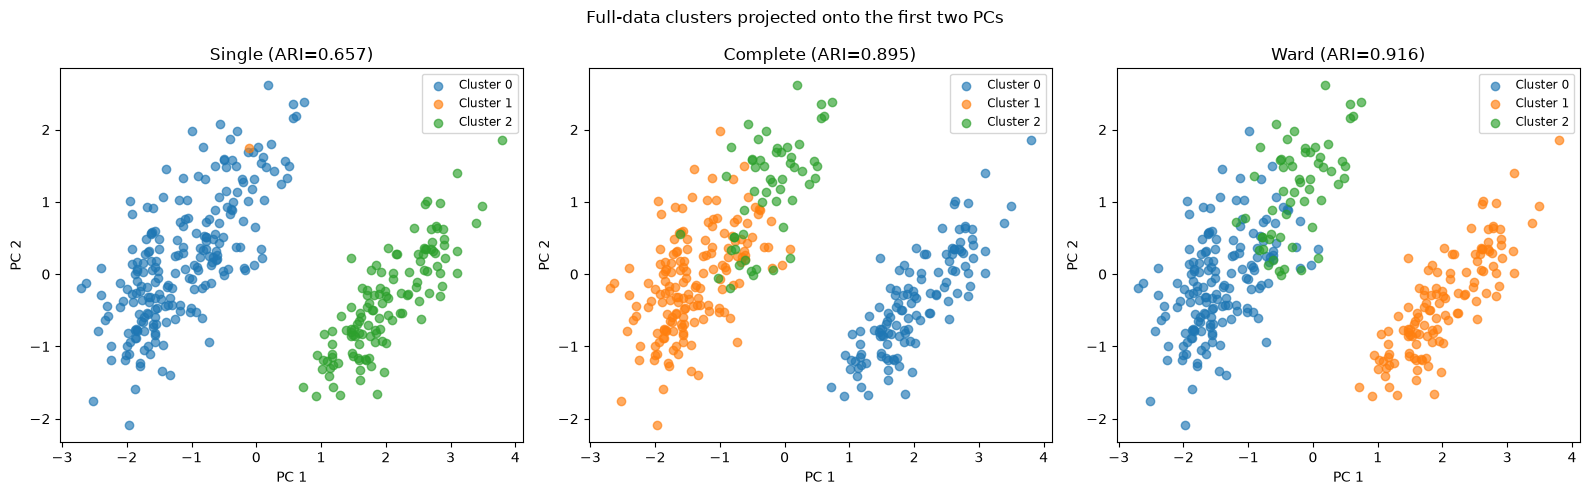

Linkage comparison:
 Linkage  Adjusted Rand index
    ward               0.9159
complete               0.8949
  single               0.6572
Conclusion: ward linkage has the highest adjusted Rand index (0.916) on this run. Single linkage can chain nearby observations, while complete linkage favours compact groups and Ward linkage tends to form similarly sized, low-variance clusters.


In [2]:
pca = PCA(n_components=2, random_state=SEED)
points_2d = pca.fit_transform(X_scaled)
ari_rows = []
contingency_tables = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for axis, method in zip(axes, linkage_methods):
    labels = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(X_scaled)
    score = adjusted_rand_score(species, labels)
    contingency = pd.crosstab(species, labels, rownames=['Actual species'], colnames=['Cluster'])
    contingency_tables[method] = contingency
    ari_rows.append({'Linkage': method, 'Adjusted Rand index': score})
    print(f'--- {method.capitalize()} linkage: ARI = {score:.4f} ---')
    print(contingency.to_string())
    for cluster_id in np.unique(labels):
        mask = labels == cluster_id
        axis.scatter(points_2d[mask, 0], points_2d[mask, 1], label=f'Cluster {cluster_id}', alpha=0.65)
    axis.set_title(f'{method.capitalize()} (ARI={score:.3f})')
    axis.set_xlabel('PC 1')
    axis.set_ylabel('PC 2')
    axis.legend(fontsize='small')
fig.suptitle('Full-data clusters projected onto the first two PCs')
fig.tight_layout()
fig.savefig(FIGURES / 'exp12_cluster_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

ari_table = pd.DataFrame(ari_rows).sort_values('Adjusted Rand index', ascending=False)
print('Linkage comparison:')
print(ari_table.to_string(index=False, float_format=lambda value: f'{value:.4f}'))
ari_table.to_csv(RESULTS / 'exp12_linkage_comparison.csv', index=False)
for method, contingency in contingency_tables.items():
    contingency.to_csv(RESULTS / f'exp12_{method}_contingency.csv')
best = ari_table.iloc[0]
print(f"Conclusion: {best['Linkage']} linkage has the highest adjusted Rand index ({best['Adjusted Rand index']:.3f}) on this run. Single linkage can chain nearby observations, while complete linkage favours compact groups and Ward linkage tends to form similarly sized, low-variance clusters.")

## Observation

Use the printed metrics, tables, plots, and predictions above as the measured observations for this run.

## Result

State the result using the actual output above and relate it to the experiment aim.